# Case Study 1 — Analytical strategy based on reduced EEG features (R)

This is the **R implementation** of Case Study 1. It implements the
analysis described in Section 4.1 of the companion paper. The same
analysis is also available as
[Python code](../../../python/CaseStudy_1/CaseStudy_1.ipynb).

The research question is:

> *Are the amplitude and latency of specific ERP components associated with neuropsychological performance and demographic characteristics in post-stroke patients?*

Two well-characterised ERP components are used:
- **N400** — a negative deflection ~400 ms post-stimulus, indexing semantic
  processing (Kutas & Federmeier, 2011)
- **P300** — a positive deflection ~300 ms post-target, indexing attentional
  resource allocation (Polich, 2007)

From each component we consider **amplitude** (mean µV within a predefined
time window) and **latency** (ms of peak amplitude), yielding four
participant-level neural predictors.

As it usually happens in real life, data are delivered in two different files: `dataset_NPSY.csv` and `dataset_ERP.csv`.

## Pipeline

1. **Data Wrangling** — load, inspect, check ranges, missing data, distributions,
   outliers
2. **Analysis** — descriptive stats, bivariate correlations, multiple regression,
   post-hoc diagnostics
3. **Export** — save tables and figures

## How this code is built

Like almost any real analysis, this notebook combines two things:

1. **Functions from established packages** - the
   [tidyverse](https://www.tidyverse.org/) (`readr`, `dplyr`, `tidyr`,
   `purrr`, `stringr`, `ggplot2`) to read, reshape and plot the data,
   `broom` to turn models into tables, `car` and `psych` for specific
   statistics (VIF, skewness/kurtosis), `patchwork` to combine plots,
   `openxlsx` for Excel export and `cli` for readable messages. Whatever a
   well-tested package already does, we don't rewrite.
2. **A few custom functions** for the steps no package does exactly the way
   we need (a range check against our clinical limits, a correlation
   heatmap with significance stars, a report-ready regression table, ...).
   They live in the [`R/`](https://github.com/SanCamilloIRCCS-OndaLab/tutorial_EEG-NPSY/tree/main/r/case1/code/R) folder next to this notebook and are loaded
   in Setup, just as you would load a small package of your own - so the
   notebook itself reads as the analysis, step by step.

The custom functions are hidden by default, but they are not a black box:
wherever one is first used, a collapsed cell lets you print its source code
(or simply open the file in `R/`).

> ⚠️ **Caution** - the custom functions in `R/` were written for this
> tutorial and are not extensively tested beyond the data used here.

## 0. Setup

Load the packages we use throughout the analysis, then our own helper
functions from the `R/` folder.

In [1]:
suppressPackageStartupMessages({
  library(tidyverse)  # readr, dplyr, tidyr, purrr, stringr, ggplot2, ...
  library(broom)      # model results as tidy tibbles
  library(patchwork)  # combine ggplot panels into one figure
  library(cli)        # readable status messages
})
# car (VIF), psych (skewness/kurtosis) and openxlsx (Excel export) are only
# needed for one function each, so we call them as pkg::fun() instead of
# attaching them - that also makes it obvious where each function comes from.

theme_set(theme_minimal())

# Our own helper functions, one file per topic in the R/ folder next to this
# notebook - loaded the way you would load a small package of your own
list.files("R", pattern = "\\.R$", full.names = TRUE) %>%
  walk(~ source(.x, keep.source = TRUE))  # keep.source: printing a helper keeps its comments

Define input/output folders

In [2]:
# Input
DATA_DIR <- "../../../data"
NPSY_CSV <- file.path(DATA_DIR, "dataset_NPSY.csv")
EEG_CSV  <- file.path(DATA_DIR, "dataset_ERP.csv")

# Output
OUTPUTS <- "../outputs"
FIGS    <- file.path(OUTPUTS, "figures")
RESULTS <- file.path(OUTPUTS, "results")
dir.create(FIGS, recursive = TRUE, showWarnings = FALSE)
dir.create(RESULTS, recursive = TRUE, showWarnings = FALSE)

---
## 1. Data Wrangling

### 1.1 Load data

The datasets are stored as separate CSV files linked by `subject_id`.

In [3]:
npsy <- read_csv(NPSY_CSV, show_col_types = FALSE)
eeg  <- read_csv(EEG_CSV, show_col_types = FALSE)

glimpse(npsy)
glimpse(eeg)

Rows: 45
Columns: 7
$ subject_id <chr> "sub-001", "sub-002", "sub-003", "sub-004", "sub-005", "sub…
$ age        <dbl> 74, 62, 55, 68, 58, 62, 70, 72, 71, 72, 57, 49, 70, 66, 58,…
$ sex        <dbl> 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0,…
$ criq       <dbl> 78, 95, 94, 97, 103, 107, 91, 80, 107, 107, 78, 95, 100, 11…
$ apacs      <dbl> 0.54, 0.67, 0.93, 0.40, 0.72, 0.86, 0.58, 0.48, 0.76, 0.57,…
$ att_matr   <dbl> 25, 38, 42, 28, 27, 39, 37, 22, 41, 29, 31, 45, 28, 46, 31,…
$ moca       <dbl> 24, 21, 30, 13, 30, 8, 25, 18, 27, 30, 22, 26, 19, 11, 21, …


Rows: 45
Columns: 5
$ subject_id <chr> "sub-001", "sub-002", "sub-003", "sub-004", "sub-005", "sub…
$ n400_amp   <dbl> 3.111, 1.794, 4.587, 3.168, 3.604, 3.785, 2.160, 3.751, 2.6…
$ n400_lat   <dbl> 458.7, 415.3, 403.6, 457.2, 434.4, 405.4, 419.8, 460.1, 408…
$ p300_amp   <dbl> 14.671, 12.818, 13.659, 12.911, 8.635, 12.412, 13.068, 13.4…
$ p300_lat   <dbl> 515.5, 408.0, 314.6, 454.2, 353.4, 332.0, 401.1, 430.1, 363…


Let's inspect the datasets looking at the first rows: each row stores the NPSY/EEG data of a single subject.

In [4]:
head(npsy)
head(eeg)

subject_id,age,sex,criq,apacs,att_matr,moca
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
sub-001,74,0,78,0.54,25,24
sub-002,62,1,95,0.67,38,21
sub-003,55,1,94,0.93,42,30
sub-004,68,0,97,0.40,28,13
sub-005,58,1,103,0.72,27,30
sub-006,62,0,107,0.86,39,8


subject_id,n400_amp,n400_lat,p300_amp,p300_lat
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
sub-001,3.111,458.7,14.671,515.5
sub-002,1.794,415.3,12.818,408.0
sub-003,4.587,403.6,13.659,314.6
sub-004,3.168,457.2,12.911,454.2
sub-005,3.604,434.4,8.635,353.4
sub-006,3.785,405.4,12.412,332.0


To create a single dataset we need to merge on `subject_id` the data collected for each subject

In [5]:
df <- inner_join(npsy, eeg, by = "subject_id")
cli_alert_info("Merged: {nrow(df)} subjects x {ncol(df)} variables")
head(df)

ℹ Merged: 45 subjects x 11 variables



subject_id,age,sex,criq,apacs,att_matr,moca,n400_amp,n400_lat,p300_amp,p300_lat
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
sub-001,74,0,78,0.54,25,24,3.111,458.7,14.671,515.5
sub-002,62,1,95,0.67,38,21,1.794,415.3,12.818,408.0
sub-003,55,1,94,0.93,42,30,4.587,403.6,13.659,314.6
sub-004,68,0,97,0.40,28,13,3.168,457.2,12.911,454.2
sub-005,58,1,103,0.72,27,30,3.604,434.4,8.635,353.4
sub-006,62,0,107,0.86,39,8,3.785,405.4,12.412,332.0


### 1.2 Initial inspection

We check dataset dimensions, column types, and basic descriptive statistics.

**Expected clinical ranges:**

| Variable           | Expected range  |
|--------------------|-----------------|
| Age                | 18–100 years    |
| CRIq               | 70–130          |
| N400 amplitude     | 1–6 µV          |
| N400 latency       | 350–500 ms      |
| P300 amplitude     | 5–20 µV         |
| P300 latency       | 300–500 ms      |
| APACS              | 0–1             |
| Attentive Matrices | 0–60            |
| MoCA               | 0–30            |

In [6]:
summary(df)

  subject_id             age              sex              criq       
 Length:45          Min.   : 49.00   Min.   :0.0000   Min.   : 74.00  
 Class :character   1st Qu.: 60.00   1st Qu.:0.0000   1st Qu.: 89.00  
 Mode  :character   Median : 65.00   Median :0.0000   Median : 95.00  
                    Mean   : 66.91   Mean   :0.4889   Mean   : 95.82  
                    3rd Qu.: 70.00   3rd Qu.:1.0000   3rd Qu.:104.50  
                    Max.   :150.00   Max.   :1.0000   Max.   :119.00  
                                                      NA's   :1       
     apacs           att_matr          moca          n400_amp     
 Min.   :0.3900   Min.   : 3.00   Min.   : 8.00   Min.   : 1.794  
 1st Qu.:0.6000   1st Qu.:25.00   1st Qu.:18.00   1st Qu.: 2.827  
 Median :0.6900   Median :31.00   Median :22.00   Median : 3.530  
 Mean   :0.6922   Mean   :31.53   Mean   :21.77   Mean   : 3.985  
 3rd Qu.:0.7600   3rd Qu.:38.00   3rd Qu.:26.00   3rd Qu.: 4.048  
 Max.   :0.9300   Max.   :48.0

From the automatic R summary we see that all parameters are within the expected ranges.

However looking at each variable is not the most suitable way to validate data: we can perform a simple automatic check on the allowed ranges.

In [7]:
# Expected physiological/clinical limits for each variable
ranges <- tribble(
  ~variable,  ~min, ~max,
  "age",        18,  100,
  "criq",       70,  130,
  "n400_amp",  0.5,    8,
  "n400_lat",  300,  550,
  "p300_amp",    3,   25,
  "p300_lat",  250,  550,
  "apacs",       0,    1,
  "att_matr",    0,   60,
  "moca",        0,   30
)

range_check <- check_ranges(df, ranges)
range_check

if (all(range_check$ok)) {
  cli_alert_success("All values within expected ranges.")
} else {
  cli_alert_warning("Values outside the expected range in: {.val {range_check$variable[!range_check$ok]}}")
}

variable,min,max,n_below,n_above,ok
<chr>,<dbl>,<dbl>,<int>,<int>,<lgl>
age,18.0,100,0,1,FALSE
criq,70.0,130,0,0,TRUE
n400_amp,0.5,8,0,1,FALSE
n400_lat,300.0,550,0,0,TRUE
p300_amp,3.0,25,0,0,TRUE
p300_lat,250.0,550,0,2,FALSE
apacs,0.0,1,0,0,TRUE
att_matr,0.0,60,0,0,TRUE
moca,0.0,30,0,0,TRUE


! Values outside the expected range in: "age", "n400_amp", and "p300_lat"



In [8]:
# Want to see how it works? Printing a function shows its source code.
print(check_ranges)

function(df, ranges) {
  ranges %>%
    filter(variable %in% names(df)) %>%
    mutate(
      n_below = map2_int(variable, min, ~ sum(df[[.x]] < .y, na.rm = TRUE)),
      n_above = map2_int(variable, max, ~ sum(df[[.x]] > .y, na.rm = TRUE)),
      ok      = n_below == 0 & n_above == 0
    )
}


### 1.3 Missing data

Missing data are common in clinical neuropsychological datasets — they can
arise from fatigue, incomplete testing, or participant dropout. Strategies
include:

- **Listwise deletion** (exclude participants with any missing value) —
  simple, but reduces sample size and may bias estimates if data are not
  missing completely at random (MCAR).
- **Multiple imputation** (e.g., MICE, see the `mice` package) — preserves
  sample size and is valid under the weaker assumption of missing at
  random (MAR). Generally preferred in clinical samples.

Our synthetic dataset has complete data for all 40 participants, so no
imputation is needed here. The code below would work with either scenario.

Visual inspection of missing data patterns:

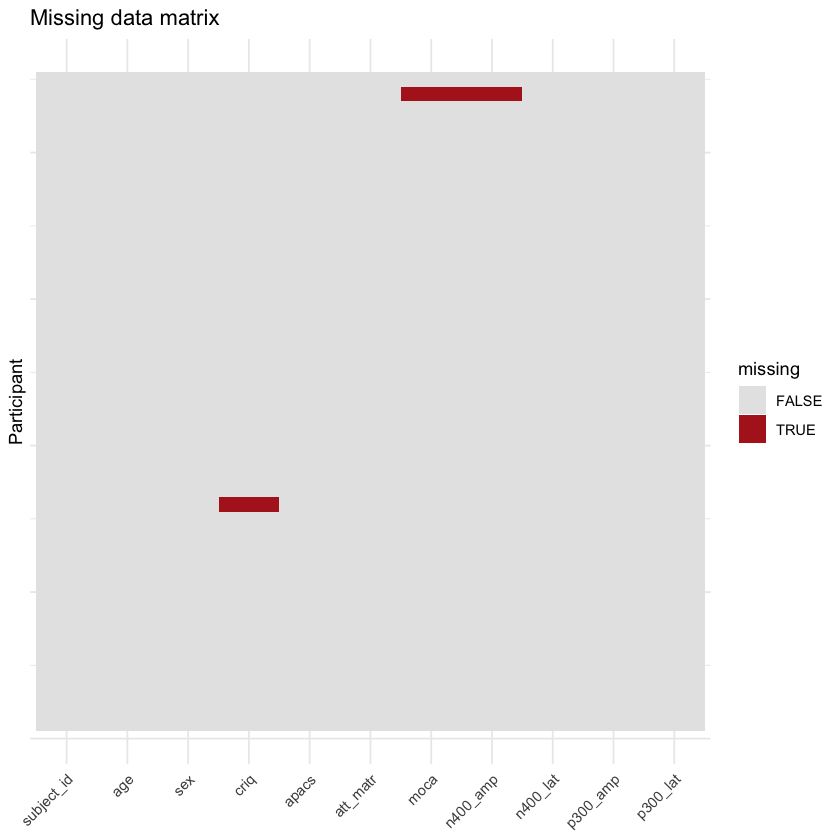

In [9]:
fig_missing <- plot_missingness(df)
fig_missing

In [10]:
# Want to see how it works? Printing a function shows its source code.
print(plot_missingness)

function(df) {
  df %>%
    mutate(across(everything(), is.na), .row = row_number()) %>%
    pivot_longer(-.row, names_to = "variable", values_to = "missing") %>%
    mutate(variable = factor(variable, levels = names(df))) %>%
    ggplot(aes(variable, .row, fill = missing)) +
    geom_tile() +
    scale_fill_manual(values = c(`FALSE` = "grey90", `TRUE` = "firebrick")) +
    labs(title = "Missing data matrix", x = NULL, y = "Participant") +
    theme(axis.text.y = element_blank(),
          axis.text.x = element_text(angle = 45, hjust = 1))
}


In [11]:
df %>%
  summarise(across(everything(), ~ sum(is.na(.x)))) %>%
  pivot_longer(everything(), names_to = "variable", values_to = "n_missing") %>%
  mutate(rate = scales::percent(n_missing / nrow(df), accuracy = 0.1))

variable,n_missing,rate
<chr>,<int>,<chr>
subject_id,0,0.0%
age,0,0.0%
sex,0,0.0%
criq,1,2.2%
apacs,0,0.0%
att_matr,0,0.0%
moca,1,2.2%
n400_amp,1,2.2%
n400_lat,0,0.0%


> **What do we see in the plot?**
>
> Each row is a participant, each column a variable; a highlighted cell
> would mark a missing value. Here the matrix is empty and the
> per-column rates above all read 0% — this synthetic dataset has no
> missing data by construction, so there's nothing to impute or
> exclude. In a real dataset, scattered missingness would support
> listwise deletion; missingness concentrated in specific participants
> or variables would be a reason to consider imputation instead.

### 1.4 Distribution check

More than just plotting the data we can already perform a quality check by looking at the Q-Q plots, and running the Shapiro-Wilk normality test. This guides later decisions about
transformations and correlation methods.

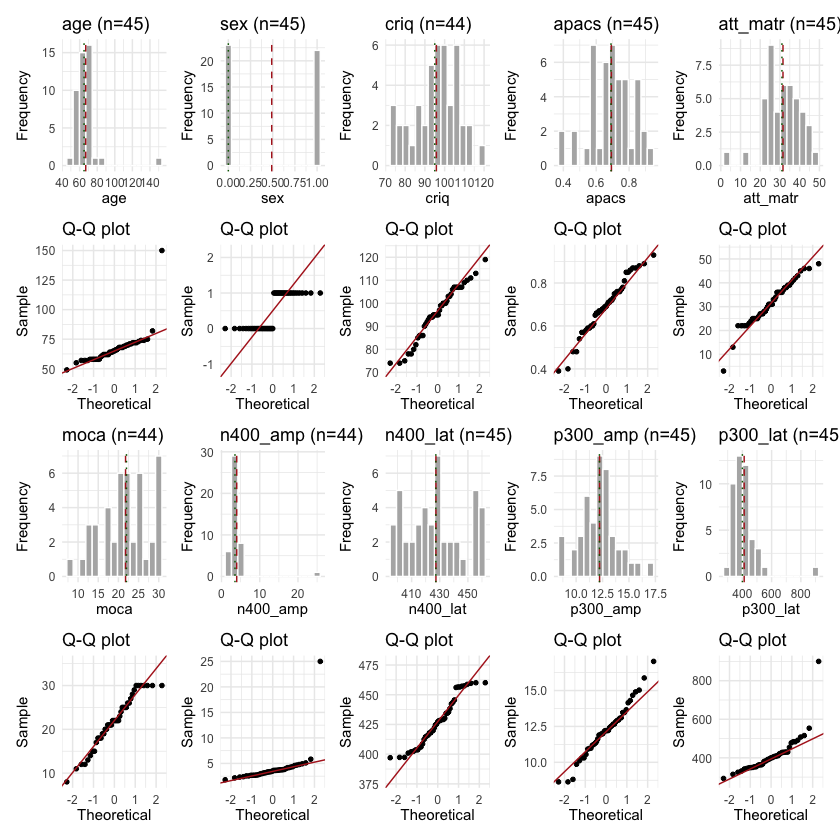

In [12]:
vars <- c("age", "sex", "criq", "apacs", "att_matr", "moca", "n400_amp", "n400_lat", "p300_amp", "p300_lat")

fig_dist <- plot_distributions(df, vars)
fig_dist

In [13]:
# Want to see how it works? Printing a function shows its source code.
print(plot_distributions)

function(df, vars, ncol = 5) {
  hist_panel <- function(var) {
    v <- tibble(value = df[[var]]) %>% drop_na()
    ggplot(v, aes(value)) +
      geom_histogram(bins = 15, fill = "grey70", color = "white") +
      geom_vline(xintercept = mean(v$value), color = "firebrick", linetype = "dashed") +
      geom_vline(xintercept = median(v$value), color = "darkgreen", linetype = "dotted") +
      labs(title = str_glue("{var} (n={nrow(v)})"), x = var, y = "Frequency") +
      theme_minimal(base_size = 9)
  }

  qq_panel <- function(var) {
    v <- tibble(value = df[[var]]) %>% drop_na()
    ggplot(v, aes(sample = value)) +
      stat_qq(size = 1) +
      stat_qq_line(color = "firebrick") +
      labs(title = "Q-Q plot", x = "Theoretical", y = "Sample") +
      theme_minimal(base_size = 9)
  }

  panels <- split(vars, ceiling(seq_along(vars) / ncol)) %>%
    map(~ c(map(.x, hist_panel), map(.x, qq_panel))) %>%
    list_flatten()

  wrap_plots(panels, ncol = ncol)
}
<bytecode: 0x126207b58>


> **What do we see in the plot?**
>
> ***Histogram*** — a roughly symmetric, bell-shaped curve suggests normality. Strong skewness (long tail to one side) or a U-shape would be a warning sign.
>
> ***Q-Q plot*** — points should fall along the diagonal line if the data are normally distributed. Key departures:
>
> *Both ends curve away from the line* → heavy tails (more extreme values than a normal distribution would predict)
>
> *S-shaped curve* → skewed distribution (left-skewed if the curve goes below then above the line; right-skewed if the reverse)
>
> *Points deviating in the middle only* → unusual peakedness (kurtosis)

In [14]:
# Shapiro-Wilk normality test, plus skewness and kurtosis, for every variable
df %>%
  select(all_of(vars)) %>%
  pivot_longer(everything(), names_to = "variable") %>%
  drop_na(value) %>%
  mutate(variable = factor(variable, levels = vars)) %>%
  group_by(variable) %>%
  summarise(
    n    = n(),
    mean = mean(value),
    sd   = sd(value),
    W    = shapiro.test(value)$statistic,
    p    = shapiro.test(value)$p.value,
    skew = psych::skew(value, type = 2),
    kurt = psych::kurtosi(value, type = 2)
  )

variable,n,mean,sd,W,p,skew,kurt
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
age,45,66.9111111,14.2618726,0.5593120,2.057779e-10,4.61869093,26.95887324
sex,45,0.4888889,0.5055250,0.6368170,2.615780e-09,0.04600329,-2.09302326
criq,44,95.8181818,11.2048011,0.9699864,3.023045e-01,-0.28207562,-0.53140124
apacs,45,0.6922222,0.1267225,0.9747049,4.234566e-01,-0.33755368,-0.02132485
att_matr,45,31.5333333,8.9914100,0.9627466,1.554043e-01,-0.54669040,1.09383956
moca,44,21.7727273,5.8899348,0.9532501,7.273251e-02,-0.34129764,-0.53523071
n400_amp,44,3.9845227,3.3506104,0.3471032,9.881607e-13,5.98647569,38.18125326
n400_lat,45,427.2755556,20.0690983,0.9329717,1.196122e-02,0.24950685,-1.05183797
p300_amp,45,12.2181111,1.7885116,0.9806644,6.466671e-01,0.25171548,0.53001934


**Interpretation:** all Shapiro-Wilk tests are non-significant (p > 0.05) and skewness values are well below |0.6|, so the variables are approximately normal. Minor scatter in the Q-Q plots is expected with n = 40 and does not indicate a problem.

### 1.5 Outlier detection

Flag values beyond ±3 standard deviations. We inspect flagged cases and note
whether they are data-entry errors or genuine extremes.

In [15]:
outliers <- flag_outliers_z(df, vars, threshold = 3)
outliers

subject_id,variable,value,z
<chr>,<chr>,<dbl>,<dbl>
sub-024,age,150,5.825945
sub-043,att_matr,3,-3.173399
sub-019,n400_amp,25,6.272134
sub-036,p300_lat,900,5.223805


In [16]:
# Want to see how it works? Printing a function shows its source code.
print(flag_outliers_z)

function(df, vars, threshold = 3, id = "subject_id") {
  df %>%
    select(all_of(c(id, vars))) %>%
    pivot_longer(all_of(vars), names_to = "variable", values_to = "value") %>%
    group_by(variable) %>%
    mutate(z = (value - mean(value, na.rm = TRUE)) / sd(value, na.rm = TRUE)) %>%
    ungroup() %>%
    filter(abs(z) > threshold) %>%
    arrange(factor(variable, levels = vars))
}


**Decision rule:** If clinically suspicious outliers exist, we run the
analysis with and without them as a sensitivity check and report both.

### 1.6 Cleaning dataset

Let's remove the missing data and the outliers.

There are three outliers that are not plausible data: Age 150, N400
Amplitude 25 uV, P300 latency 900ms. We will remove these subjects.

However the value of 3 for attentive matrices is very low but it is also
very plausible in a patient dataset, therefore we will keep this
outlier.

In [17]:
# Outliers: exclude only the implausible ones found in Section 1.5 - keep
# the att_matr outlier, since it is a plausible (if low) clinical value
implausible <- outliers %>%
  filter(variable %in% c("age", "n400_amp", "p300_lat")) %>%
  pull(subject_id)

# Participants to exclude: any missing value, or an implausible outlier
excluded <- df %>%
  filter(if_any(all_of(vars), is.na) | subject_id %in% implausible)
excluded %>% select(subject_id, all_of(vars))

df <- df %>% anti_join(excluded, by = "subject_id")
cli_alert_info("Excluded {nrow(excluded)} participants - {nrow(df)} remaining.")

subject_id,age,sex,criq,apacs,att_matr,moca,n400_amp,n400_lat,p300_amp,p300_lat
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
sub-016,72,0,NA,0.48,22,18,3.751,460.1,13.469,430.1
sub-019,58,1,103,0.72,27,30,25.000,434.4,8.635,353.4
sub-024,150,0,100,0.66,31,21,2.549,429.2,10.306,483.4
sub-036,62,0,74,0.67,25,20,3.626,456.5,11.983,900.0
sub-044,57,1,95,0.75,36,NA,NA,397.3,12.206,363.9


ℹ Excluded 5 participants - 40 remaining.



---
## 2. Analysis

### 2.1 Descriptive statistics (Table 1)

We describe each variable by looking at its mean, standard deviation, and range of values

In [18]:
num2 <- function(x) formatC(x, format = "f", digits = 2)  # 2 decimals, e.g. "65.30"

table1 <- df %>%
  select(all_of(vars)) %>%
  pivot_longer(everything(), names_to = "Variable") %>%
  drop_na(value) %>%
  mutate(Variable = factor(Variable, levels = vars)) %>%
  group_by(Variable) %>%
  summarise(
    n     = n(),
    Value = str_c(num2(mean(value)), " ± ", num2(sd(value))),
    Range = str_c("[", num2(min(value)), ", ", num2(max(value)), "]")
  ) %>%
  mutate(Variable = as.character(Variable))
table1

Variable,n,Value,Range
<chr>,<int>,<chr>,<chr>
age,40,65.30 ± 6.63,"[49.00, 82.00]"
sex,40,0.50 ± 0.51,"[0.00, 1.00]"
criq,40,96.10 ± 11.15,"[74.00, 119.00]"
apacs,40,0.70 ± 0.13,"[0.39, 0.93]"
att_matr,40,31.95 ± 9.30,"[3.00, 48.00]"
moca,40,21.73 ± 6.00,"[8.00, 30.00]"
n400_amp,40,3.51 ± 0.87,"[1.79, 5.83]"
n400_lat,40,426.25 ± 19.48,"[397.00, 460.10]"
p300_amp,40,12.33 ± 1.77,"[8.63, 17.03]"


### 2.2 Bivariate correlations (ERP × NPSY)

We compute Pearson correlations between all the variables, but the interesting values are the ones between the ERP features and the
neuropsychological outcomes. The heatmap shows r values with significance
stars (* p<0.05, ** p<0.01, *** p<0.001).

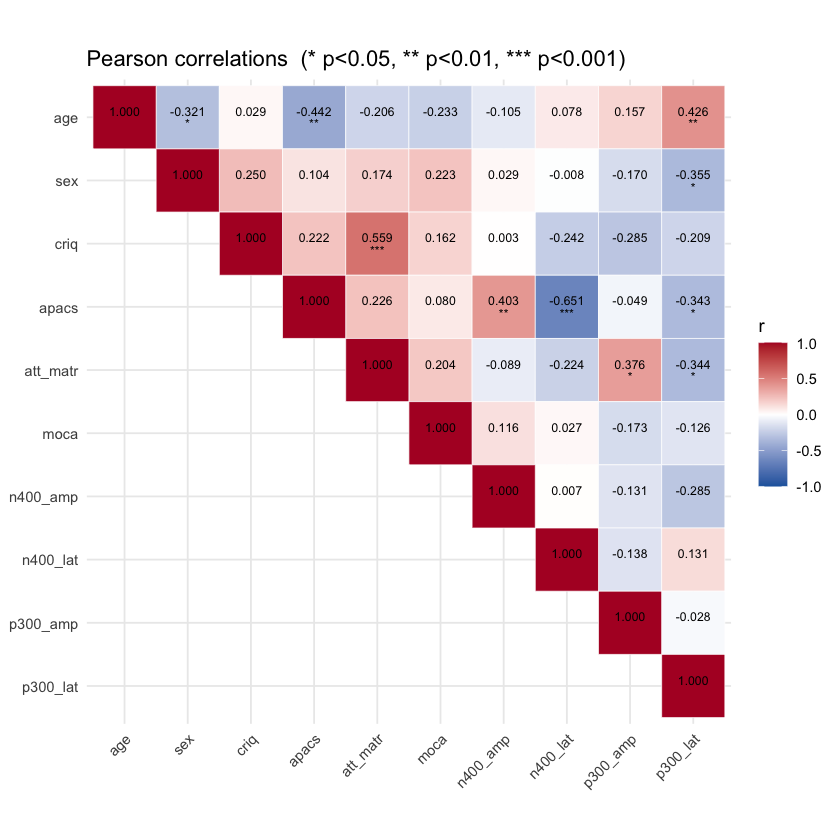

In [19]:
cor_tbl <- cor_pairs(df, vars)   # one row per pair: var1, var2, r, p

fig_corr <- plot_cor_heatmap(cor_tbl, vars)
fig_corr

In [20]:
# Want to see how it works? Printing a function shows its source code.
print(cor_pairs)
print(plot_cor_heatmap)

function(df, vars) {
  complete <- df %>%
    select(all_of(vars)) %>%
    drop_na()

  expand_grid(i = seq_along(vars), j = seq_along(vars)) %>%
    filter(i < j) %>%
    mutate(
      var1 = vars[i],
      var2 = vars[j],
      test = map2(var1, var2, ~ tidy(cor.test(complete[[.x]], complete[[.y]])))
    ) %>%
    unnest(test) %>%
    select(var1, var2, r = estimate, p = p.value)
}


function(cor_tbl, vars) {
  diagonal <- tibble(var1 = vars, var2 = vars, r = 1, p = 1)

  bind_rows(cor_tbl, diagonal) %>%
    mutate(
      stars = case_when(p < 0.001 ~ "***", p < 0.01 ~ "**", p < 0.05 ~ "*", TRUE ~ ""),
      label = str_c(formatC(r, format = "f", digits = 3), "\n", stars),
      x     = factor(var2, levels = vars),
      y     = factor(var1, levels = rev(vars))
    ) %>%
    ggplot(aes(x, y, fill = r)) +
    geom_tile(color = "white") +
    geom_text(aes(label = label), size = 2.6, lineheight = 0.85) +
    scale_fill_gradient2(low = "#2166ac", mid = "white", high = "#b2182b",
                         midpoint = 0, limits = c(-1, 1)) +
    coord_fixed() +
    labs(title = "Pearson correlations  (* p<0.05, ** p<0.01, *** p<0.001)", x = NULL, y = NULL) +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
}
<bytecode: 0x13038e6a0>


> **What do we see in the plot?**
>
> Each cell shows the Pearson correlation coefficient (*r*) between a pair of variables. Colours indicate direction: red = positive, blue = negative. Intensity reflects strength (closer to ±1 = stronger).
>
> ***Pearson correlation*** - Values range from −1 (perfect negative) to +1 (perfect positive). A value near 0 means no linear relationship.
>
> ***Significance*** - Stars indicate whether the correlation is statistically significant: * p<0.05, ** p<0.01, *** p<0.001. The lower the p-value, the stronger the evidence that the correlation is not due to chance.

#### Key hypothesised associations

Based on the literature, we focus on two key pairs and generate scatter plots
with regression lines and 95 % confidence bands.

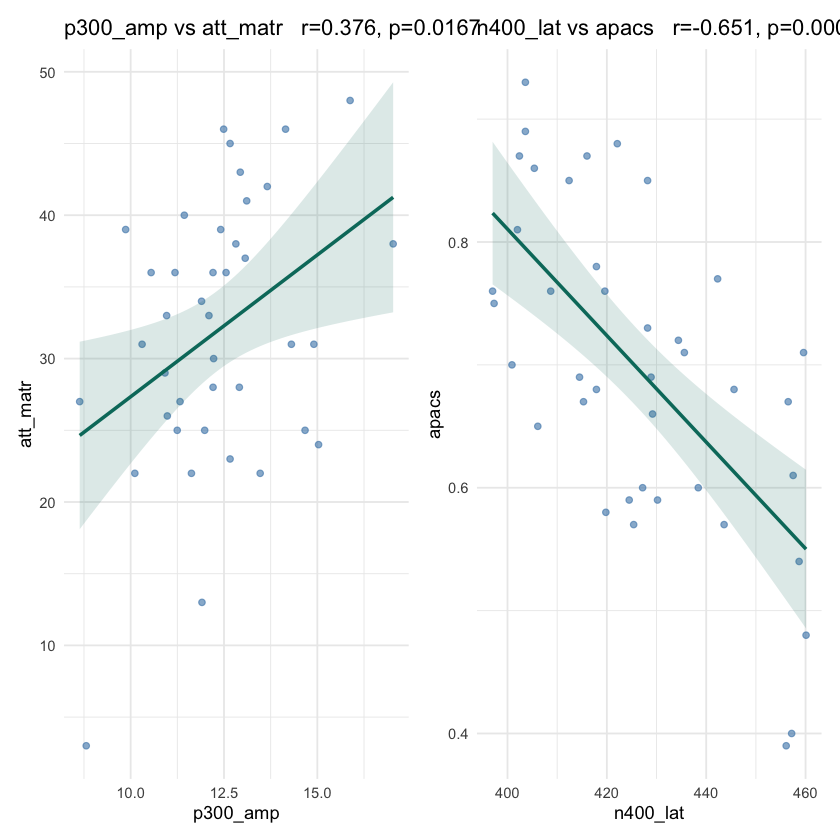

In [21]:
fig_scatter <- plot_scatter_lm(df, "p300_amp", "att_matr") +
  plot_scatter_lm(df, "n400_lat", "apacs")
fig_scatter

In [22]:
# Want to see how it works? Printing a function shows its source code.
print(plot_scatter_lm)

function(df, x, y) {
  v <- df %>% select(all_of(c(x, y))) %>% drop_na()
  ct <- tidy(cor.test(v[[x]], v[[y]]))
  r <- formatC(ct$estimate, format = "f", digits = 3)
  p <- formatC(ct$p.value, format = "f", digits = 4)

  ggplot(v, aes(.data[[x]], .data[[y]])) +
    geom_point(alpha = 0.6, color = "steelblue") +
    geom_smooth(method = "lm", formula = y ~ x,
                color = "#00796B", fill = "#00796B", alpha = 0.15) +
    labs(title = str_glue("{x} vs {y}   r={r}, p={p}"), x = x, y = y)
}
<bytecode: 0x161ad8b70>


> **What do we see in the plot?**
>
> Each dot shows the values of one participant.
>
> The **regression line** shows the best-fit linear relationship — upward slope = positive association, flat = none.
>
> The **shaded band** is the 95 % confidence interval: narrower = more precise estimate, wider = more uncertainty (typically at the extremes). If the band includes a horizontal line, the slope may not be significant.
>
> The **r** value (Pearson correlation coefficient) quantifies strength (−1 to +1); **p** tests whether it is significantly different from zero.

### 2.3 General linear models

We fit three models, each with a different structure. This reflects the
reality of clinical research: sometimes we have a clear theoretical
prediction, sometimes we explore, and sometimes we learn from our mistakes
and simplify.

---

#### APACS - A theory-driven model

Descrizione di modello teorico per APACS

*APACS ~ N400_lat + N400_amp + Age*

In [23]:
mod_apacs <- glm(apacs ~ n400_lat + n400_amp + age, data = df, family = gaussian())
summary(mod_apacs)


Call:
glm(formula = apacs ~ n400_lat + n400_amp + age, family = gaussian(), 
    data = df)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  2.7338107  0.2755661   9.921 7.68e-12 ***
n400_lat    -0.0041682  0.0005948  -7.008 3.21e-08 ***
n400_amp     0.0548452  0.0132786   4.130 0.000206 ***
age         -0.0069354  0.0017570  -3.947 0.000351 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for gaussian family taken to be 0.005201438)

    Null deviance: 0.65508  on 39  degrees of freedom
Residual deviance: 0.18725  on 36  degrees of freedom
AIC: -91.052

Number of Fisher Scoring iterations: 2


#### Attentive Matrices - A model with no a priori knowledge

Now we want to build a model for attentive matrices.

As known by the theory, and also shown in the previous correlation plot, attentive matrices are correlated to P300, education (CRIq), and age.

But our dataset includes much more variables, therefore one idea could be *bigger is better: let's put everything together*

So we can try to fit a kitchen-sink model using all the data as covariates: *AttentiveMatrices ~ P300_lat + P300_amp + N400_lat + N400_amp + Age + Sex + CRIq*

We fit this model only to see what happens when theory is ignored and every available variable is thrown in — not to use its p-values to decide afterwards which variables to keep (see below).

In [24]:
mod_att_matr_full <- glm(att_matr ~ p300_lat + p300_amp + n400_lat + n400_amp + age + sex + criq,
                          data = df, family = gaussian())
summary(mod_att_matr_full)


Call:
glm(formula = att_matr ~ p300_lat + p300_amp + n400_lat + n400_amp + 
    age + sex + criq, family = gaussian(), data = df)

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) -51.65230   27.62387  -1.870  0.07068 .  
p300_lat     -0.01082    0.01827  -0.592  0.55772    
p300_amp      3.37630    0.53689   6.289 4.72e-07 ***
n400_lat      0.04021    0.04604   0.873  0.38892    
n400_amp     -0.64179    1.02223  -0.628  0.53456    
age          -0.45527    0.14983  -3.039  0.00471 ** 
sex          -0.61895    1.87509  -0.330  0.74348    
criq          0.63951    0.08822   7.249 3.09e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for gaussian family taken to be 27.3741)

    Null deviance: 3375.90  on 39  degrees of freedom
Residual deviance:  875.97  on 32  degrees of freedom
AIC: 254.97

Number of Fisher Scoring iterations: 2


#### Attentive Matrices - A theory-guided, parsimonious model

The kitchen-sink model above shows the cost of ignoring theory: several
predictors are far from significant, and entering redundant or
theoretically unmotivated variables inflates standard errors and
destabilises the coefficients.

Importantly, we do **not** decide which variables to keep by looking at
*these* p-values — that would be post-hoc pruning, a form of circular
reasoning: the same data would first be searched to select the model and
then reused to test it, inflating the apparent evidence for whatever
survives. Instead we go back to theory and to the earlier bivariate
analysis (Section 2.2): P300 amplitude, age, and CRIq are the established
covariates for attentional performance, so those are the predictors we
keep *a priori*. N400 amplitude/latency and P300 latency are dropped
because there is no theoretical reason to expect them to explain attentive
matrices performance specifically, and `sex` is dropped on the same a
priori grounds — not because it failed to reach significance above.

*Attentive Matrices ~ P300_amp + Age + CRIq*

In [25]:
mod_att_matr_pars <- glm(att_matr ~ p300_amp + age + criq, data = df, family = gaussian())
summary(mod_att_matr_pars)


Call:
glm(formula = att_matr ~ p300_amp + age + criq, family = gaussian(), 
    data = df)

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) -39.83626   12.39673  -3.213 0.002765 ** 
p300_amp      3.37819    0.48259   7.000 3.28e-08 ***
age          -0.46156    0.12350  -3.737 0.000644 ***
criq          0.62718    0.07566   8.289 7.25e-10 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for gaussian family taken to be 25.34659)

    Null deviance: 3375.90  on 39  degrees of freedom
Residual deviance:  912.48  on 36  degrees of freedom
AIC: 248.61

Number of Fisher Scoring iterations: 2


This theory-guided model has fewer predictors, and — as a consequence, not
as the reason we chose them — all of them are significant and the model is
more stable. Because the selection was made a priori rather than by
trimming non-significant terms, the improved fit (a lower AIC, despite — in fact because of — fewer parameters) can be read as genuine evidence in favour of
parsimony, rather than as an artefact of having searched the data for
whichever subset happens to look best.

> **Takeaway**
>
> More variables does not mean a better model — and *how* you choose which
> variables to drop matters just as much as the decision to drop them.
> Selecting predictors *after* seeing that they are not significant in a
> bigger model is a form of post hoc pruning, which is circular: the same
> data end up being used both to choose the model and to test it, which
> inflates the apparent evidence for whatever predictors remain.
>
> Here the predictors were instead chosen **a priori**, from theory and
> from the earlier correlation analysis (Section 2.2), before looking at
> any p-value from the kitchen-sink model. The kitchen-sink model was fit
> only to *illustrate* the cost of ignoring theory — inflated standard
> errors, an unstable intercept — not to guide which variables to keep.
> That the resulting theory-driven model also turns out to fit at least as
> well (a lower AIC, all coefficients significant, and a simpler,
> more interpretable structure) is a welcome confirmation, not the
> justification for the choice.

### 2.4 Assumption checking (post-hoc)

Fitting a model is not the last step: linear regression relies on a few
assumptions, and good practice is to check them **after** fitting, before
trusting the coefficients. We do this here for the final, parsimonious
Attentive Matrices model (`att_matr ~ p300_amp + age + criq`).

- **Linearity & homoscedasticity** — residuals plotted against fitted values
  should scatter randomly around zero, with no funnel shape or curve.
- **Normality of residuals** — a Q-Q plot of the residuals should follow the
  diagonal (same logic as the Q-Q plots in Section 1.4, now applied to the
  model's errors instead of the raw variables).
- **Influential observations** — Cook's distance flags participants who, on
  their own, pull the fitted model strongly in one direction. A common rule
  of thumb is to inspect points above 4/n.
- **Multicollinearity** — the Variance Inflation Factor (VIF) quantifies how
  much a predictor's variance is inflated by correlation with the other
  predictors. VIF > 5 is a moderate concern, VIF > 10 is severe. Unlike a
  manual VIF calculation, R's `car::vif()` never includes the intercept in
  the first place, so there is nothing to exclude here.

Predictor,VIF
<chr>,<dbl>
p300_amp,1.122159
age,1.031568
criq,1.095338


ℹ Participants above the 4/n Cook's distance threshold: 3 (max Cook's D = 0.236)



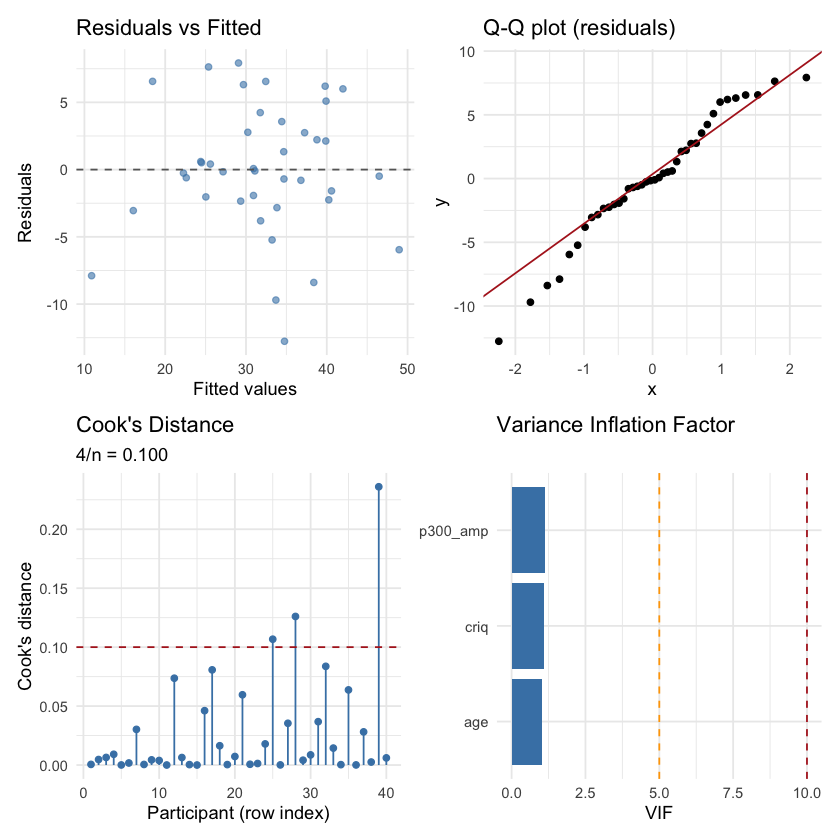

In [26]:
mod <- mod_att_matr_pars

fig_diag <- plot_model_diagnostics(mod)
fig_diag

vif_table <- car::vif(mod) %>% enframe(name = "Predictor", value = "VIF")
vif_table

cooks <- augment(mod)$.cooksd
cli_alert_info(
  "Participants above the 4/n Cook's distance threshold: {sum(cooks > 4 / nobs(mod))} (max Cook's D = {round(max(cooks), 3)})"
)

In [27]:
# Want to see how it works? Printing a function shows its source code.
print(plot_model_diagnostics)

function(model) {
  aug <- augment(model) %>% mutate(.index = row_number())
  n <- nobs(model)
  vif_tbl <- car::vif(model) %>% enframe(name = "Predictor", value = "VIF")

  p_resid <- ggplot(aug, aes(.fitted, .resid)) +
    geom_point(alpha = 0.6, color = "steelblue") +
    geom_hline(yintercept = 0, linetype = "dashed", color = "grey40") +
    labs(title = "Residuals vs Fitted", x = "Fitted values", y = "Residuals")

  p_qq <- ggplot(aug, aes(sample = .resid)) +
    stat_qq() +
    stat_qq_line(color = "firebrick") +
    labs(title = "Q-Q plot (residuals)")

  p_cooks <- ggplot(aug, aes(.index, .cooksd)) +
    geom_segment(aes(xend = .index, yend = 0), color = "steelblue") +
    geom_point(color = "steelblue") +
    geom_hline(yintercept = 4 / n, color = "firebrick", linetype = "dashed") +
    labs(title = "Cook's Distance", x = "Participant (row index)", y = "Cook's distance",
         subtitle = str_c("4/n = ", formatC(4 / n, format = "f", digits = 3)))

  p_vif <- ggplot(vif_tbl, 

> **What do we see in the plot?**
>
> ***Residuals vs Fitted*** — no funnel shape or curve should be visible; a
> random scatter around zero supports linearity and constant variance
> (homoscedasticity).
>
> ***Q-Q plot (residuals)*** — points should lie close to the diagonal;
> systematic curvature would suggest non-normal errors.
>
> ***Cook's distance*** — a handful of points above the 4/n line is not
> unusual with n = 40 and, on its own, is not a red flag: what matters is
> whether any point stands out with a much larger value than the rest (a
> useful check is to refit the model without that participant and see
> whether the coefficients change materially).
>
> ***VIF*** — values close to 1 mean each predictor carries mostly
> independent information; here `p300_amp`, `age`, and `criq` all sit well
> below the VIF = 5 caution threshold, so multicollinearity is not a
> concern for this model.

**Interpretation:** for the parsimonious Attentive Matrices model, the
diagnostics are reassuring — residuals show no obvious pattern, the Q-Q
plot is close to the diagonal, no participant has a disproportionately
large Cook's distance, and VIF values are low. This supports treating the
model's coefficients (Section 2.3) at face value.

---
## 3. Export

We now save the results that matter most for a clinical audience: the key
**figures** (as PNG images, ready to paste into a report or a slide) and
the key **tables** (as both `.csv` — universal, opens anywhere — and
`.xlsx` — a single Excel workbook with one sheet per table, easier to
browse for those who are not used to statistical software).

Nothing here is recomputed: we simply save the figures and tables already
produced above.

### 3.1 Figures

We save the figures produced earlier, one PNG per figure.

In [28]:
figures <- tibble(
  filename = c("A_missingness.png", "B_distributions.png", "C_correlations.png",
               "D_key_associations.png", "E_diagnostics_attentive_matrices.png"),
  plot     = list(fig_missing, fig_dist, fig_corr, fig_scatter, fig_diag),
  width    = c(10, 20, 9, 12, 11),
  height   = c(3, 16, 7, 5, 9)
)

pwalk(figures, function(filename, plot, width, height) {
  path <- file.path(FIGS, filename)
  ggsave(path, plot, width = width, height = height, dpi = 150, bg = "white")
  cli_alert_success("Saved {.file {path}}")
})

✔ Saved ../outputs/figures/A_missingness.png



✔ Saved ../outputs/figures/B_distributions.png



✔ Saved ../outputs/figures/C_correlations.png



✔ Saved ../outputs/figures/D_key_associations.png



✔ Saved ../outputs/figures/E_diagnostics_attentive_matrices.png



### 3.2 Tables

We export four tables:

1. **Descriptive statistics** (`table1`, already built in Section 2.1)
2. **Bivariate correlations** — every pair of variables, one row per pair
   (long/tidy format, easier to filter and sort in Excel than a matrix)
3. **Regression results** — coefficients, standard errors, p-values and
   95% CI for all three models (APACS, and both Attentive Matrices models)
4. **Multicollinearity check (VIF)** — for the parsimonious Attentive
   Matrices model (Section 2.4)

Each table gets a `Significant (p<0.05)` column so it is immediately clear,
without reading p-values, which associations/predictors reach conventional
significance.

In [29]:
# Table 2 - bivariate correlations, one row per unique pair of variables
table2_correlations <- cor_tbl %>%
  transmute(
    `Variable 1` = var1,
    `Variable 2` = var2,
    r,
    `p-value` = p,
    `Significant (p<0.05)` = p < 0.05
  )
head(table2_correlations)

Variable 1,Variable 2,r,p-value,Significant (p<0.05)
<chr>,<chr>,<dbl>,<dbl>,<lgl>
age,sex,-0.32076961,0.043583785,TRUE
age,criq,0.02871583,0.860378823,FALSE
age,apacs,-0.44225738,0.004271818,TRUE
age,att_matr,-0.20633880,0.201454655,FALSE
age,moca,-0.23297195,0.147977000,FALSE
age,n400_amp,-0.10502923,0.518935561,FALSE


In [30]:
# Table 3 - regression coefficients for all three fitted models
table3_regression <- bind_rows(
  tidy_glm_wald(mod_apacs, "APACS (theory-driven)"),
  tidy_glm_wald(mod_att_matr_full, "Attentive Matrices (kitchen-sink)"),
  tidy_glm_wald(mod_att_matr_pars, "Attentive Matrices (parsimonious)")
)
table3_regression

Outcome,Predictor,Estimate,Std. Error,p-value,CI_lower,CI_upper,Significant (p<0.05)
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
APACS (theory-driven),(Intercept),2.733810687,0.275566134,7.681474e-12,2.193711e+00,3.273910384,TRUE
APACS (theory-driven),n400_lat,-0.004168185,0.000594790,3.206130e-08,-5.333952e-03,-0.003002418,TRUE
APACS (theory-driven),n400_amp,0.054845209,0.013278574,2.057195e-04,2.881968e-02,0.080870736,TRUE
APACS (theory-driven),age,-0.006935368,0.001756969,3.514614e-04,-1.037896e-02,-0.003491772,TRUE
Attentive Matrices (kitchen-sink),(Intercept),-51.652297835,27.623873752,7.067881e-02,-1.057941e+02,2.489499832,FALSE
Attentive Matrices (kitchen-sink),p300_lat,-0.010822586,0.018268045,5.577243e-01,-4.662730e-02,0.024982124,FALSE
Attentive Matrices (kitchen-sink),p300_amp,3.376296480,0.536885519,4.718415e-07,2.324020e+00,4.428572761,TRUE
Attentive Matrices (kitchen-sink),n400_lat,0.040214361,0.046040257,3.889198e-01,-5.002289e-02,0.130451606,FALSE
Attentive Matrices (kitchen-sink),n400_amp,-0.641793315,1.022226428,5.345648e-01,-2.645320e+00,1.361733668,FALSE


In [31]:
# Want to see how it works? Printing a function shows its source code.
print(tidy_glm_wald)

function(model, outcome) {
  z <- qnorm(0.975)
  tidy(model) %>%
    transmute(
      Outcome                = outcome,
      Predictor              = term,
      Estimate               = estimate,
      `Std. Error`           = std.error,
      `p-value`              = p.value,
      CI_lower               = estimate - z * std.error,
      CI_upper               = estimate + z * std.error,
      `Significant (p<0.05)` = p.value < 0.05
    )
}
<bytecode: 0x16e1c5dd0>


In [32]:
# Table 4 - VIF table computed in Section 2.4 (Attentive Matrices, parsimonious model)
table4_vif <- vif_table
table4_vif

Predictor,VIF
<chr>,<dbl>
p300_amp,1.122159
age,1.031568
criq,1.095338


In [33]:
tables <- list(
  "table1_descriptives.csv" = table1,
  "table2_correlations.csv" = table2_correlations,
  "table3_regression.csv"   = table3_regression,
  "table4_vif.csv"          = table4_vif
)

iwalk(tables, function(table, filename) {
  path <- file.path(RESULTS, filename)
  write_csv(table, path)
  cli_alert_success("Saved {.file {path}}")
})

# The same four tables in one Excel workbook, one sheet each
xlsx_path <- file.path(RESULTS, "CaseStudy_1_results.xlsx")
openxlsx::write.xlsx(
  list(Descriptives = table1, Correlations = table2_correlations,
       Regression = table3_regression, VIF = table4_vif),
  xlsx_path, overwrite = TRUE
)
cli_alert_success("Saved {.file {xlsx_path}}")

✔ Saved ../outputs/results/table1_descriptives.csv



✔ Saved ../outputs/results/table2_correlations.csv



✔ Saved ../outputs/results/table3_regression.csv



✔ Saved ../outputs/results/table4_vif.csv



✔ Saved ../outputs/results/CaseStudy_1_results.xlsx



---
## 4. Strengths and limitations of this approach (Section 4.2.3)

**Strengths:**
- Reduces high-dimensional EEG to **4 interpretable scalar features** per
  participant — theoretically grounded, easy to communicate
- Uses **well-established statistical models** (OLS regression) familiar to
  clinical researchers
- The N400 and P300 have **decades of validation** across neurological
  populations (Kutas & Federmeier, 2011; Polich, 2007)

**Limitations:**
- Strong **a priori decisions** about time windows and electrode sets may
  miss atypical or distributed neural patterns — especially relevant in
  stroke patients whose ERP topography may differ from normative expectations
- **Trial-to-trial variability** is discarded (only mean amplitude and peak
  latency are kept), which may itself carry clinically relevant information
- The **hypothesis-driven** nature of the approach means it will not detect
  effects outside the predefined features — for broader exploration, see
  Case Study 2 (spectral analysis)

> For a full discussion, see Section 4.2 of the companion paper.

---

*Generated for the EEG-NPSY tutorial. The analysis uses standard R
packages plus a few helper functions in the `R/` folder next to this
notebook - all of it open for inspection.*